In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

from analyse_exploratoire import analyse_exploratoire

In [71]:
data_regularite=pd.read_excel("data/reglarite-mensuelle-tgv-nationale.xlsx")
data_regularite.head(10)

,Date,Régularité composite,Ponctualité origine
0,2015-01,91.627358,85.280538
1,2015-02,90.325652,84.248184
2,2015-03,93.421794,87.453249
3,2015-04,90.801173,85.342175
4,2015-05,91.373510,85.048795
5,2015-06,87.697086,82.612883
6,2015-07,84.887154,79.819406
7,2015-08,89.102128,82.234832
8,2015-09,89.545803,84.638101
9,2015-10,91.013911,85.124313


In [72]:
data_regularite.info()

<class 'pandas.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  138 non-null    str    
 1   Régularité composite  138 non-null    float64
 2   Ponctualité origine   138 non-null    float64
dtypes: float64(2), str(1)
memory usage: 3.4 KB


In [73]:
variables_descr=["Régularité composite", "Ponctualité origine"]
data_regularite[variables_descr].describe()

,Régularité composite,Ponctualité origine
count,138.000000,138.000000
mean,88.685763,83.137958
std,2.931835,3.376082
min,77.851061,72.269528
25%,87.000754,81.296658
50%,89.075756,83.413237
75%,90.743996,85.266584
max,94.559508,90.732140


Première description:

Notre dataset provient de l'open Data de la SNCF. Il comporte **138** observations sur **3** variables qui sont:
- "Régularité composite": elle correspond au pourcentage de trains arrivés à l'heure à leur gare de destination. Elle est mesurée à la gare d'arrivée. 
- "Ponctualité origine" : elle correspond au pourcentage de trains qui partent à l'heure. Elle est mesurée à la gare de départ.
- "Date": correspond au mois et année d'observation. Le dataset couvre la période de janvier 2015 à juin 2026.

Si on regarde un peu les statistiques, on peut voir qu'on a entre 72% et 90.73% des trains qui partent à l'heure et 77% à 94.56%  des trains arrivent à l'heure à destination.
En moyenne 88.69% des trains arrivent à l'heure et 83.14% des trains partent à l'heure.

Le dernier point est que le dataset ne comporte pas de valeurs manquantes ni de doublons.

NB: La notion de "arrivée à l'heure" n'est pas prise au sens strict des termes. Elle signifie plutôt "arrivée dans un délai jugé acceptable selon la durée du trajet (5, 10, 15 min de tolérance).

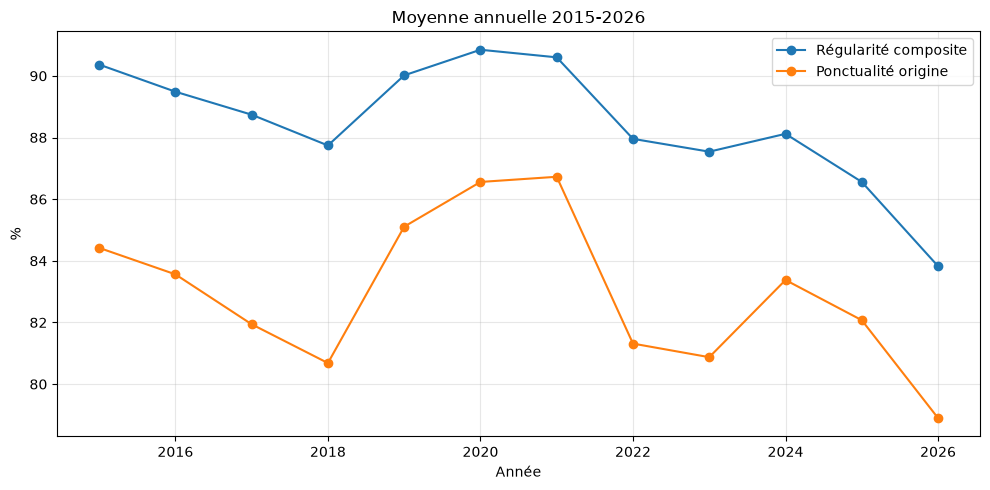

In [10]:
data_annee = data.groupby('Annee')[['Régularité composite', 'Ponctualité origine']].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(data_annee['Annee'], data_annee['Régularité composite'], marker='o', label='Régularité composite')
plt.plot(data_annee['Annee'], data_annee['Ponctualité origine'], marker='o', label='Ponctualité origine')

plt.title('Moyenne annuelle 2015-2026')
plt.xlabel('Année')
plt.ylabel('%')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

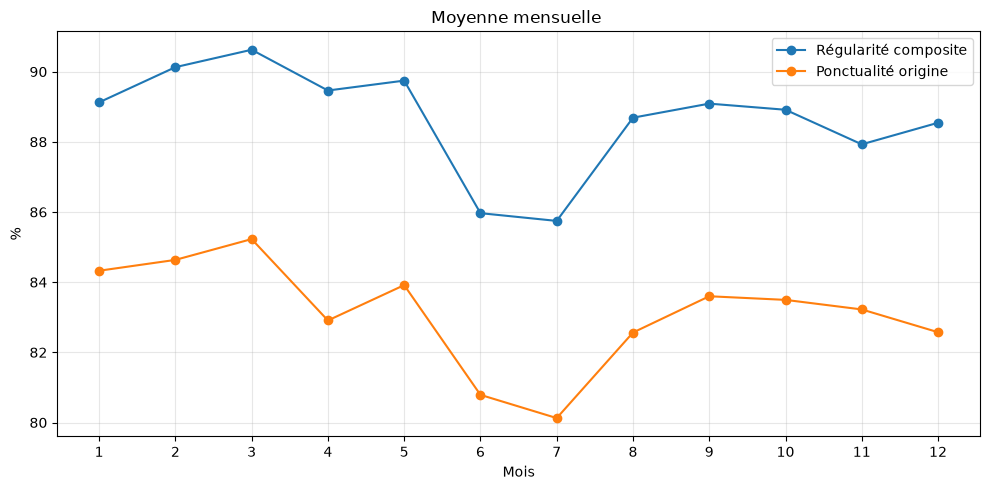

In [11]:
data_mois = data.groupby('Mois')[['Régularité composite', 'Ponctualité origine']].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(data_mois['Mois'], data_mois['Régularité composite'], marker='o', label='Régularité composite')
plt.plot(data_mois['Mois'], data_mois['Ponctualité origine'], marker='o', label='Ponctualité origine')

plt.title('Moyenne mensuelle ')
plt.xlabel('Mois')
plt.ylabel('%')
plt.xticks(range(1, 13))  # affiche 1 à 12 sur l'axe X, pas de valeurs décimales
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Analyse des graphiques**

- Le graphique par année révèle une évolution en trois phases plutôt qu'une tendance linéaire.

De 2015 à 2018, la régularité baisse, avec un creux en 2018 (87,74%). Entre 2019 et 2021, elle remonte nettement pour atteindre son point 
haut en 2020 (90,85%), avant de rechuter dès 2022 (87,96%) et de continuer à se dégrader jusqu'en 2026 (83,83% sur les 6 premiers mois).

Le pic observé en 2020-2021 ne traduit pas une amélioration opérationnelle de la SNCF : il coïncide avec la pandémie de Covid-19 et la forte baisse du trafic ferroviaire durant 
cette période. Moins de circulations signifie mécaniquement moins de risques de retard et de correspondances perturbées, indépendamment de tout effort d'amélioration du réseau. 
Ce pic est donc un artefact de contexte, à ne pas interpréter comme une tendance de fond.

- Le graphique par mois fait apparaître un schéma saisonnier récurrent : juin et juillet sont systématiquement les mois les moins 
performants, tandis que mars ressort comme le meilleur mois.

Cette baisse estivale est cohérente avec deux phénomènes structurels du réseau ferroviaire : la période de travaux d'été (maintenance des voies, souvent programmée 
hors saison hivernale) et le pic de trafic voyageurs lié aux départs en vacances, qui sature davantage le réseau et augmente le risque de retards en cascade.



## On peut à présent regarder le dataset détaillé sur lequel nous ferons toute notre étude

In [2]:
data=pd.read_csv("data/regularite-mensuelle-tgv-aqst.csv",sep=";")
data.head(10)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386
5,2018-01,National,ST MALO,PARIS MONTPARNASSE,158,92,0,NaN,2,1.225000,...,6,4.763978,3,1,22.222222,66.666667,0.000000,11.111111,0.000000,0.000000
6,2018-01,National,TOULOUSE MATABIAU,PARIS MONTPARNASSE,257,184,0,NaN,23,11.221739,...,26,7.510507,12,3,59.090909,22.727273,4.545455,9.090909,4.545455,0.000000
7,2018-01,National,VANNES,PARIS MONTPARNASSE,156,278,1,NaN,168,5.120437,...,25,6.241487,11,3,24.137931,44.827586,20.689655,3.448276,3.448276,3.448276
8,2018-01,National,REIMS,PARIS EST,46,230,1,NaN,93,7.432796,...,20,3.538937,3,0,17.948718,41.025641,20.512821,5.128205,0.000000,15.384615
9,2018-01,National,DOUAI,PARIS NORD,77,197,3,NaN,39,8.032906,...,10,5.046907,5,3,36.363636,18.181818,22.727273,18.181818,4.545455,0.000000


In [3]:
print(data.columns.tolist())

['Date', 'Service', 'Gare de départ', "Gare d'arrivée", 'Durée moyenne du trajet', 'Nombre de circulations prévues', 'Nombre de trains annulés', 'Commentaire annulations', 'Nombre de trains en retard au départ', 'Retard moyen des trains en retard au départ', 'Retard moyen de tous les trains au départ', 'Commentaire retards au départ', "Nombre de trains en retard à l'arrivée", "Retard moyen des trains en retard à l'arrivée", "Retard moyen de tous les trains à l'arrivée", "Commentaire retards à l'arrivée", 'Nombre trains en retard > 15min', 'Retard moyen trains en retard > 15 (si liaison concurrencée par vol)', 'Nombre trains en retard > 30min', 'Nombre trains en retard > 60min', 'Prct retard pour causes externes', 'Prct retard pour cause infrastructure', 'Prct retard pour cause gestion trafic', 'Prct retard pour cause matériel roulant', 'Prct retard pour cause gestion en gare et réutilisation de matériel', 'Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, corre

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12544 entries, 0 to 12543
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12544 non-null  str    
 1   Service                                                                                      12544 non-null  str    
 2   Gare de départ                                                                               12544 non-null  str    
 3   Gare d'arrivée                                                                               12544 non-null  str    
 4   Durée moyenne du trajet                                                                      12544 non-null  int64  
 5   Nombre de circulations prévues             

In [5]:
print(data["Date"].min(), data["Date"].max())

2018-01 2026-06


**Premier regard sur le dataset**

Notre dataset détaille, pour chaque liaison TGV et chaque mois entre Janvier 2018 et Juin 2026, les volumes des circulations, retards et annulations, ainsi que la répartition des causes de retard.
Il comporte 12544 observations décrites sur 26 colonnes.
On peut scinder en différentes catégories les colonnes présentes.
On a le tableau suivant:
### Catégorisation des variables

| Catégorie | Variables | Description |
|---|---|---|
| **Identification** | `Date`, `Service`, `Gare de départ`, `Gare d'arrivée`, `Durée moyenne du trajet` | Décrivent le contexte de chaque observation : quelle liaison, à quel mois, quel type de service, et la durée du trajet |
| **Volumes** | `Nombre de circulations prévues`, `Nombre de trains annulés`, `Nombre de trains en retard au départ`, `Nombre de trains en retard à l'arrivée`, `Nombre trains en retard > 15min`, `Nombre trains en retard > 30min`, `Nombre trains en retard > 60min` | Comptages bruts de trains (circulations, annulations, retards par palier de sévérité) |
| **Retards (minutes)** | `Retard moyen des trains en retard au départ`, `Retard moyen de tous les trains au départ`, `Retard moyen des trains en retard à l'arrivée`, `Retard moyen de tous les trains à l'arrivée`, `Retard moyen trains en retard > 15 (si liaison concurrencée par vol)` | Durées moyennes de retard, à distinguer selon qu'elles sont calculées sur les seuls trains en retard ou sur l'ensemble des trains |
| **Causes de retard (%)** | `Prct retard pour causes externes`, `Prct retard pour cause infrastructure`, `Prct retard pour cause gestion trafic`, `Prct retard pour cause matériel roulant`, `Prct retard pour cause gestion en gare et réutilisation de matériel`, `Prct retard pour cause prise en compte voyageurs` | Répartition en pourcentage des causes structurelles de retard |
| **Commentaires** | `Commentaire annulations`, `Commentaire retards au départ`, `Commentaire retards à l'arrivée` | Texte libre décrivant ponctuellement des incidents marquants |

Avant de continuer regardons de près les colonnes "commentaires".

In [6]:
data["Commentaire annulations"].unique()

array([nan])

In [7]:
data["Commentaire retards au départ"].unique()

array([nan])

In [8]:
data["Commentaire retards à l'arrivée"].nunique()

302

In [9]:
data["Commentaire retards à l'arrivée"].isna().mean()*100

np.float64(94.43558673469387)

**Les commentaires concernant les annulations et les retards au départ sont vides. Ils n'apportent aucune information. On peut les supprimer définitivement**
**Par contre, les commentaires concernant les retards à l'arrivé ne sont pas tous vides. Environ 5.5% ont été renseignés**
**On ne les utilisera pas pour notre modèle car statistiquement negligeable mais ils pourront servir d'interprétations des résultas**

In [10]:
colonnes_comm=["Commentaire annulations", "Commentaire retards au départ","Commentaire retards à l'arrivée"]
data=data.drop(columns=colonnes_comm)

In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12544 entries, 0 to 12543
Data columns (total 23 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12544 non-null  str    
 1   Service                                                                                      12544 non-null  str    
 2   Gare de départ                                                                               12544 non-null  str    
 3   Gare d'arrivée                                                                               12544 non-null  str    
 4   Durée moyenne du trajet                                                                      12544 non-null  int64  
 5   Nombre de circulations prévues             

In [12]:
#variable Date
data["Date"]=pd.to_datetime(data["Date"])
data["Mois"]=data["Date"].dt.month
data["Année"]=data["Date"].dt.year
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12544 entries, 0 to 12543
Data columns (total 25 columns):
 #   Column                                                                                       Non-Null Count  Dtype         
---  ------                                                                                       --------------  -----         
 0   Date                                                                                         12544 non-null  datetime64[us]
 1   Service                                                                                      12544 non-null  str           
 2   Gare de départ                                                                               12544 non-null  str           
 3   Gare d'arrivée                                                                               12544 non-null  str           
 4   Durée moyenne du trajet                                                                      12544 non-null  int64         

**Les colonnes commentaires ont été supprimées. Les colonnes restantes sont toutes de types numériques et object.**

**Pour plus d'informations temporelle, la variable date a été scindée en année et mois.**


**On peut regarder maintenant l'existence des données: manquantes, doublons, erreurs, etcc**

In [13]:
valeurs_manquantes = ["", " ", "NA", "N/A", "na", "n/a", "NULL", "null", "None", "none", "-","NaN"]

missing = (data.isna() | data.map(lambda x: isinstance(x, str) and x.strip() in valeurs_manquantes))

print("Valeurs manquantes :", missing.sum().sum())

Valeurs manquantes : 0


In [14]:
data.duplicated().sum()

np.int64(0)

In [15]:
data.describe()

,Date,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,...,Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",Mois,Année
count,12544,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,...,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000,12544.000000
mean,2022-03-06 06:48:54.183673,170.628508,272.623884,8.407685,86.219866,12.499854,3.175135,38.243304,35.471909,6.196906,...,13.025989,5.370615,21.897002,21.491158,20.118126,18.993447,7.762730,7.581653,6.331553,2021.733976
min,2018-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,-229.269444,0.000000,-40.109259,-472.638889,...,-44.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2018.000000
25%,2020-01-01 00:00:00,99.000000,151.000000,0.000000,22.000000,6.346596,1.226076,16.000000,25.958062,3.454553,...,4.000000,1.000000,10.714286,11.538462,10.000000,10.000000,0.000000,0.000000,3.000000,2020.000000
50%,2022-03-01 00:00:00,163.000000,230.000000,2.000000,52.000000,10.560933,2.368000,30.000000,33.777423,5.452094,...,10.000000,3.000000,19.642857,20.000000,18.461538,17.142857,5.882353,5.031800,6.000000,2022.000000
75%,2024-05-01 00:00:00,223.000000,362.000000,7.000000,126.000000,16.101225,4.031985,52.000000,42.776681,8.249353,...,18.000000,7.000000,30.252101,29.268293,28.571429,25.617573,11.398558,11.111111,9.000000,2024.000000
max,2026-06-01 00:00:00,786.000000,1100.000000,297.000000,596.000000,316.188095,115.047390,376.000000,299.600000,92.000000,...,202.000000,77.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,12.000000,2026.000000
std,NaN,87.730733,183.559230,22.089205,88.428503,11.660090,5.054562,31.826539,15.605191,6.930326,...,12.684545,6.250032,16.068989,14.914196,14.709970,13.564449,8.682545,9.451102,3.442887,2.477955


Variables à analyser attentivement:
- Nombre de trains en retard > 30 min
- Retard moyen trains en retard > 15 (si liaison concurrencée par vol)
- Retard moyen de tous les trains à l'arrivée
- Retard moyen des trains en retard à l'arrivée
- Retard moyen de tous les trains au départ

**Mais avant toute analyse, nous savons qu'il est possible d'avoir un retard moyen de trains négatif si le train arrive en avance par exemple. Mais le nombre de trains avec une valeur négative n'est pas possible. Mais explorons un peu ces variables pour voir plus clair.**

In [16]:
colonnes_retard=["Nombre trains en retard > 30min",
                "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",
                "Retard moyen de tous les trains à l'arrivée",
                "Retard moyen des trains en retard à l'arrivée",
                "Retard moyen de tous les trains au départ"]



In [17]:
(data[colonnes_retard] < 0).sum()

Nombre trains en retard > 30min                                          43
Retard moyen trains en retard > 15 (si liaison concurrencée par vol)      8
Retard moyen de tous les trains à l'arrivée                             121
Retard moyen des trains en retard à l'arrivée                             2
Retard moyen de tous les trains au départ                               170
dtype: int64

In [18]:
#nombre de trains en retard de plus de 30min
data.loc[data["Nombre trains en retard > 30min"] < 0, ["Date", "Nombre trains en retard > 30min","Service","Gare de départ","Gare d'arrivée"]]

,Date,Nombre trains en retard > 30min,Service,Gare de départ,Gare d'arrivée
10326,2025-01-01,-4,International,LAUSANNE,PARIS LYON
10329,2025-01-01,-1,National,DIJON VILLE,PARIS LYON
10330,2025-01-01,-1,National,DOUAI,PARIS NORD
10357,2025-01-01,-1,National,LE MANS,PARIS MONTPARNASSE
10358,2025-01-01,-2,National,MARSEILLE ST CHARLES,MARNE LA VALLEE
10379,2025-01-01,-1,National,LILLE,PARIS NORD
10380,2025-01-01,-44,National,LYON PART DIEU,LILLE
10381,2025-01-01,-2,National,LYON PART DIEU,MARNE LA VALLEE
10382,2025-01-01,-3,National,LYON PART DIEU,PARIS LYON
10392,2025-01-01,-1,National,QUIMPER,PARIS MONTPARNASSE


In [19]:
col = "Nombre trains en retard > 30min"
col_prevu = "Nombre de circulations prévues"

# 1. Examiner les valeurs manquantes
print("Valeurs manquantes :", data[col].isna().sum())

# 2. Examiner les valeurs négatives
print("Valeurs négatives :", data[col].lt(0).sum())

# 3. Examiner les valeurs non entières
masque_non_entier = data[col].notna() & (data[col] % 1 != 0)
print("Valeurs non entières :", masque_non_entier.sum())

# 4. Repérer les valeurs supérieures au nombre de circulations prévues
masque_superieur = data[col] > data[col_prevu]

print("Valeurs supérieures au nombre de circulations prévues :",
      masque_superieur.sum())



Valeurs manquantes : 0
Valeurs négatives : 43
Valeurs non entières : 0
Valeurs supérieures au nombre de circulations prévues : 0


Pour cette première variable, on observe que les anomalies sont présentes uniqement dans la période de Janvier 2025 à Mars 2025.
La vérification a mis en évidence 43 observations présentant des valeurs négatives soit environ 0.34% des observations. Selon la fiche descriptive du jeu de données, cette variable représente le nombre de trains dont le retard dépasse 30 minutes et est définie comme une variable entière. Une valeur négative étant incompatible avec la nature d’un dénombrement, les observations concernées ont été considérées comme invalides et doivent donc être traitées.
**Deux solutions: on les remplace par des Nan et on les impute oubien on les supprime définitivement du dataset**

In [31]:
cols_retard= [
    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",
    "Retard moyen de tous les trains à l'arrivée",
    "Retard moyen des trains en retard à l'arrivée",
    "Retard moyen de tous les trains au départ"
]


In [32]:
# Afficher les 5 observations les plus négatives
for col in cols_retard:
    print(f"\n{col}")
    display(data.loc[data[col] < 0, ["Date", "Gare de départ", "Gare d'arrivée", col]].nsmallest(5, col))


Retard moyen trains en retard > 15 (si liaison concurrencée par vol)


,Date,Gare de départ,Gare d'arrivée,Retard moyen trains en retard > 15 (si liaison concurrencée par vol)
1983,2019-04-01,MARSEILLE ST CHARLES,MADRID,-4.000000
495,2018-04-01,MARSEILLE ST CHARLES,MADRID,-2.714286
1148,2018-09-01,PARIS MONTPARNASSE,ST MALO,-2.404296
1732,2019-02-01,MARSEILLE ST CHARLES,MADRID,-1.571429
1833,2019-03-01,ZURICH,PARIS LYON,-0.601023



Retard moyen de tous les trains à l'arrivée


,Date,Gare de départ,Gare d'arrivée,Retard moyen de tous les trains à l'arrivée
2998,2019-12-01,STRASBOURG,NANTES,-472.638889
2985,2019-12-01,LYON PART DIEU,MONTPELLIER,-173.076970
3253,2020-02-01,PARIS EST,FRANCFORT,-163.041983
2877,2019-11-01,NIMES,PARIS LYON,-151.291008
2824,2019-11-01,MONTPELLIER,PARIS LYON,-150.562114



Retard moyen des trains en retard à l'arrivée


,Date,Gare de départ,Gare d'arrivée,Retard moyen des trains en retard à l'arrivée
2877,2019-11-01,NIMES,PARIS LYON,-40.109259
2824,2019-11-01,MONTPELLIER,PARIS LYON,-30.512500



Retard moyen de tous les trains au départ


,Date,Gare de départ,Gare d'arrivée,Retard moyen de tous les trains au départ
2835,2019-11-01,BARCELONA,PARIS LYON,-229.269444
2877,2019-11-01,NIMES,PARIS LYON,-112.262016
2758,2019-10-01,NIMES,PARIS LYON,-92.768307
2829,2019-11-01,VALENCE ALIXAN TGV,PARIS LYON,-69.838288
2759,2019-10-01,VALENCE ALIXAN TGV,PARIS LYON,-67.953740


In [33]:
for col in cols_retard:
    nb_negatives = data[col].lt(0).sum()
    pourcentage = nb_negatives / len(data) * 100

    print(
        f"{col} : {nb_negatives} valeurs négatives "
        f"({pourcentage:.2f} %)"
    )

Retard moyen trains en retard > 15 (si liaison concurrencée par vol) : 8 valeurs négatives (0.06 %)
Retard moyen de tous les trains à l'arrivée : 121 valeurs négatives (0.96 %)
Retard moyen des trains en retard à l'arrivée : 2 valeurs négatives (0.02 %)
Retard moyen de tous les trains au départ : 170 valeurs négatives (1.36 %)


In [35]:
nb_valeurs_negatives = data[cols_retard].lt(0).sum().sum()
nb_lignes_concernees = data[cols_retard].lt(0).any(axis=1).sum()

print("Nombre total de valeurs négatives :", nb_valeurs_negatives)
print("Nombre de lignes concernées :", nb_lignes_concernees)
print("Nombre total de lignes :", len(data))
print(
    "Pourcentage de lignes concernées :",
    f"{nb_lignes_concernees / len(data) * 100:.2f} %"
)

Nombre total de valeurs négatives : 301
Nombre de lignes concernées : 277
Nombre total de lignes : 12544
Pourcentage de lignes concernées : 2.21 %


In [36]:
df_temp = data.copy()
df_temp["Annee"] = pd.to_datetime(df_temp["Date"]).dt.year

for col in cols_retard:
    stats = df_temp.groupby("Annee")[col].agg(
        nb_observations="count",
        nb_negatives=lambda s: s.lt(0).sum()
    )
    stats["pourcentage_negatif"] = (
        stats["nb_negatives"] / stats["nb_observations"] * 100
    )
    print(f"\n{col}")
    display(stats.round(2))


Retard moyen trains en retard > 15 (si liaison concurrencée par vol)


,nb_observations,nb_negatives,pourcentage_negatif
Annee,,,
2018,1560,4,0.26
2019,1476,4,0.27
2020,1476,0,0.00
2021,1449,0,0.00
2022,1467,0,0.00
2023,1446,0,0.00
2024,1450,0,0.00
2025,1494,0,0.00
2026,726,0,0.00



Retard moyen de tous les trains à l'arrivée


,nb_observations,nb_negatives,pourcentage_negatif
Annee,,,
2018,1560,4,0.26
2019,1476,17,1.15
2020,1476,40,2.71
2021,1449,32,2.21
2022,1467,10,0.68
2023,1446,3,0.21
2024,1450,9,0.62
2025,1494,4,0.27
2026,726,2,0.28



Retard moyen des trains en retard à l'arrivée


,nb_observations,nb_negatives,pourcentage_negatif
Annee,,,
2018,1560,0,0.00
2019,1476,2,0.14
2020,1476,0,0.00
2021,1449,0,0.00
2022,1467,0,0.00
2023,1446,0,0.00
2024,1450,0,0.00
2025,1494,0,0.00
2026,726,0,0.00



Retard moyen de tous les trains au départ


,nb_observations,nb_negatives,pourcentage_negatif
Annee,,,
2018,1560,19,1.22
2019,1476,18,1.22
2020,1476,44,2.98
2021,1449,56,3.86
2022,1467,13,0.89
2023,1446,5,0.35
2024,1450,4,0.28
2025,1494,10,0.67
2026,726,1,0.14


L’analyse du jeu de données a révélé des valeurs négatives dans quatre variables relatives aux retards moyens. Dix observations au total présentaient des valeurs négatives dans les variables « Retard moyen trains en retard > 15 (si liaison concurrencée par vol) » et « Retard moyen des trains en retard à l’arrivée » : huit (0.06%) dans la première variable, dont quatre en 2018 et quatre en 2019, et deux (0.02%) dans la seconde, toutes deux en 2019. 

Par ailleurs, 170 valeurs négatives ont été relevées pour le retard moyen de tous les trains au départ (1,36 % des observations) et 121 pour le retard moyen de tous les trains à l’arrivée (0,96 %).

Selon la méthodologie de l’Autorité de la qualité de service dans les transports (AQST), le retard moyen de l’ensemble des trains est calculé en rapportant la somme des minutes de retard enregistrées au nombre total de trains concernés. Cet indicateur inclut également les trains dont le retard est inférieur ou égal au seuil de contrôle. Toutefois, la documentation consultée ne précise pas explicitement la manière dont les trains en avance sont pris en compte dans ce calcul. En conséquence, les valeurs négatives relevées dans les deux indicateurs de retard moyen de l’ensemble des trains nécessitent une vérification méthodologique avant de pouvoir être considérées comme invalides.

In [37]:
# Créer une copie du jeu de données initial
df_clean = data.copy()


# Identifier les observations contenant au moins une valeur négative
masque_negatif = df_clean[cols_retard].lt(0).any(axis=1)

# Supprimer ces observations
df_clean = df_clean.loc[~masque_negatif].copy()

# Vérifier le résultat
print("Nombre d'observations avant nettoyage :", len(data))
print("Nombre d'observations après nettoyage :", len(df_clean))
print("Nombre d'observations supprimées :", len(data) - len(df_clean))

Nombre d'observations avant nettoyage : 12544
Nombre d'observations après nettoyage : 12267
Nombre d'observations supprimées : 277


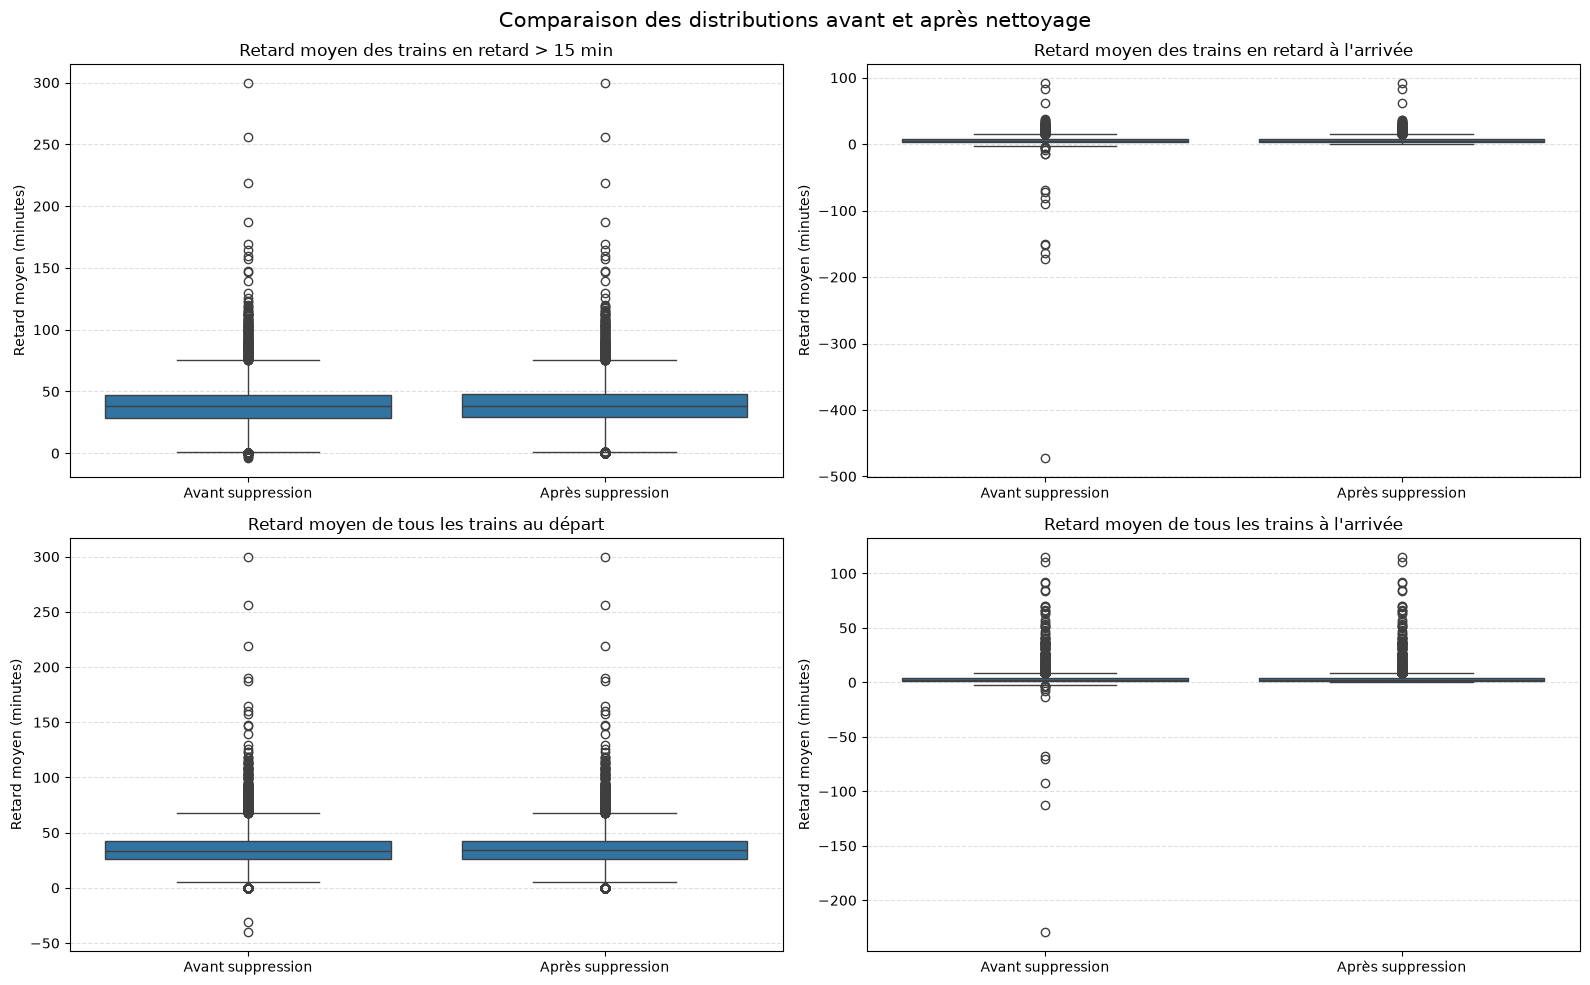

In [38]:
titres = [
    "Retard moyen des trains en retard > 15 min",
    "Retard moyen des trains en retard à l'arrivée",
    "Retard moyen de tous les trains au départ",
    "Retard moyen de tous les trains à l'arrivée"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for i, cols_retard in enumerate(cols_retard):
    ax = axes[i // 2, i % 2]

    donnees = pd.DataFrame({
        "Avant suppression": data[cols_retard].dropna().reset_index(drop=True),
        "Après suppression": df_clean[cols_retard].dropna().reset_index(drop=True)
    })

    donnees = donnees.melt(
        var_name="État du nettoyage",
        value_name="Retard moyen (minutes)"
    )

    sns.boxplot(
        data=donnees,
        x="État du nettoyage",
        y="Retard moyen (minutes)",
        ax=ax
    )

    ax.set_title(titres[i])
    ax.set_xlabel("")
    ax.set_ylabel("Retard moyen (minutes)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle(
    "Comparaison des distributions avant et après nettoyage",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [39]:
df_clean.to_csv("donnees_nettoyees.csv", index=False)

## Analyse Exploratoire des données 

ANALYSE EXPLORATOIRE : Dataset

1. Dimensions
Nombre de lignes : 12544
Nombre de colonnes : 25

2. Valeurs manquantes
Empty DataFrame
Columns: [Valeurs manquantes]
Index: []

3. Variables numériques
['Durée moyenne du trajet', 'Nombre de circulations prévues', 'Nombre de trains annulés', 'Nombre de trains en retard au départ', 'Retard moyen des trains en retard au départ', 'Retard moyen de tous les trains au départ', "Nombre de trains en retard à l'arrivée", "Retard moyen des trains en retard à l'arrivée", "Retard moyen de tous les trains à l'arrivée", 'Nombre trains en retard > 15min', 'Retard moyen trains en retard > 15 (si liaison concurrencée par vol)', 'Nombre trains en retard > 30min', 'Nombre trains en retard > 60min', 'Prct retard pour causes externes', 'Prct retard pour cause infrastructure', 'Prct retard pour cause gestion trafic', 'Prct retard pour cause matériel roulant', 'Prct retard pour cause gestion en gare et réutilisation de matériel', 'Prct retard pour cause prise en

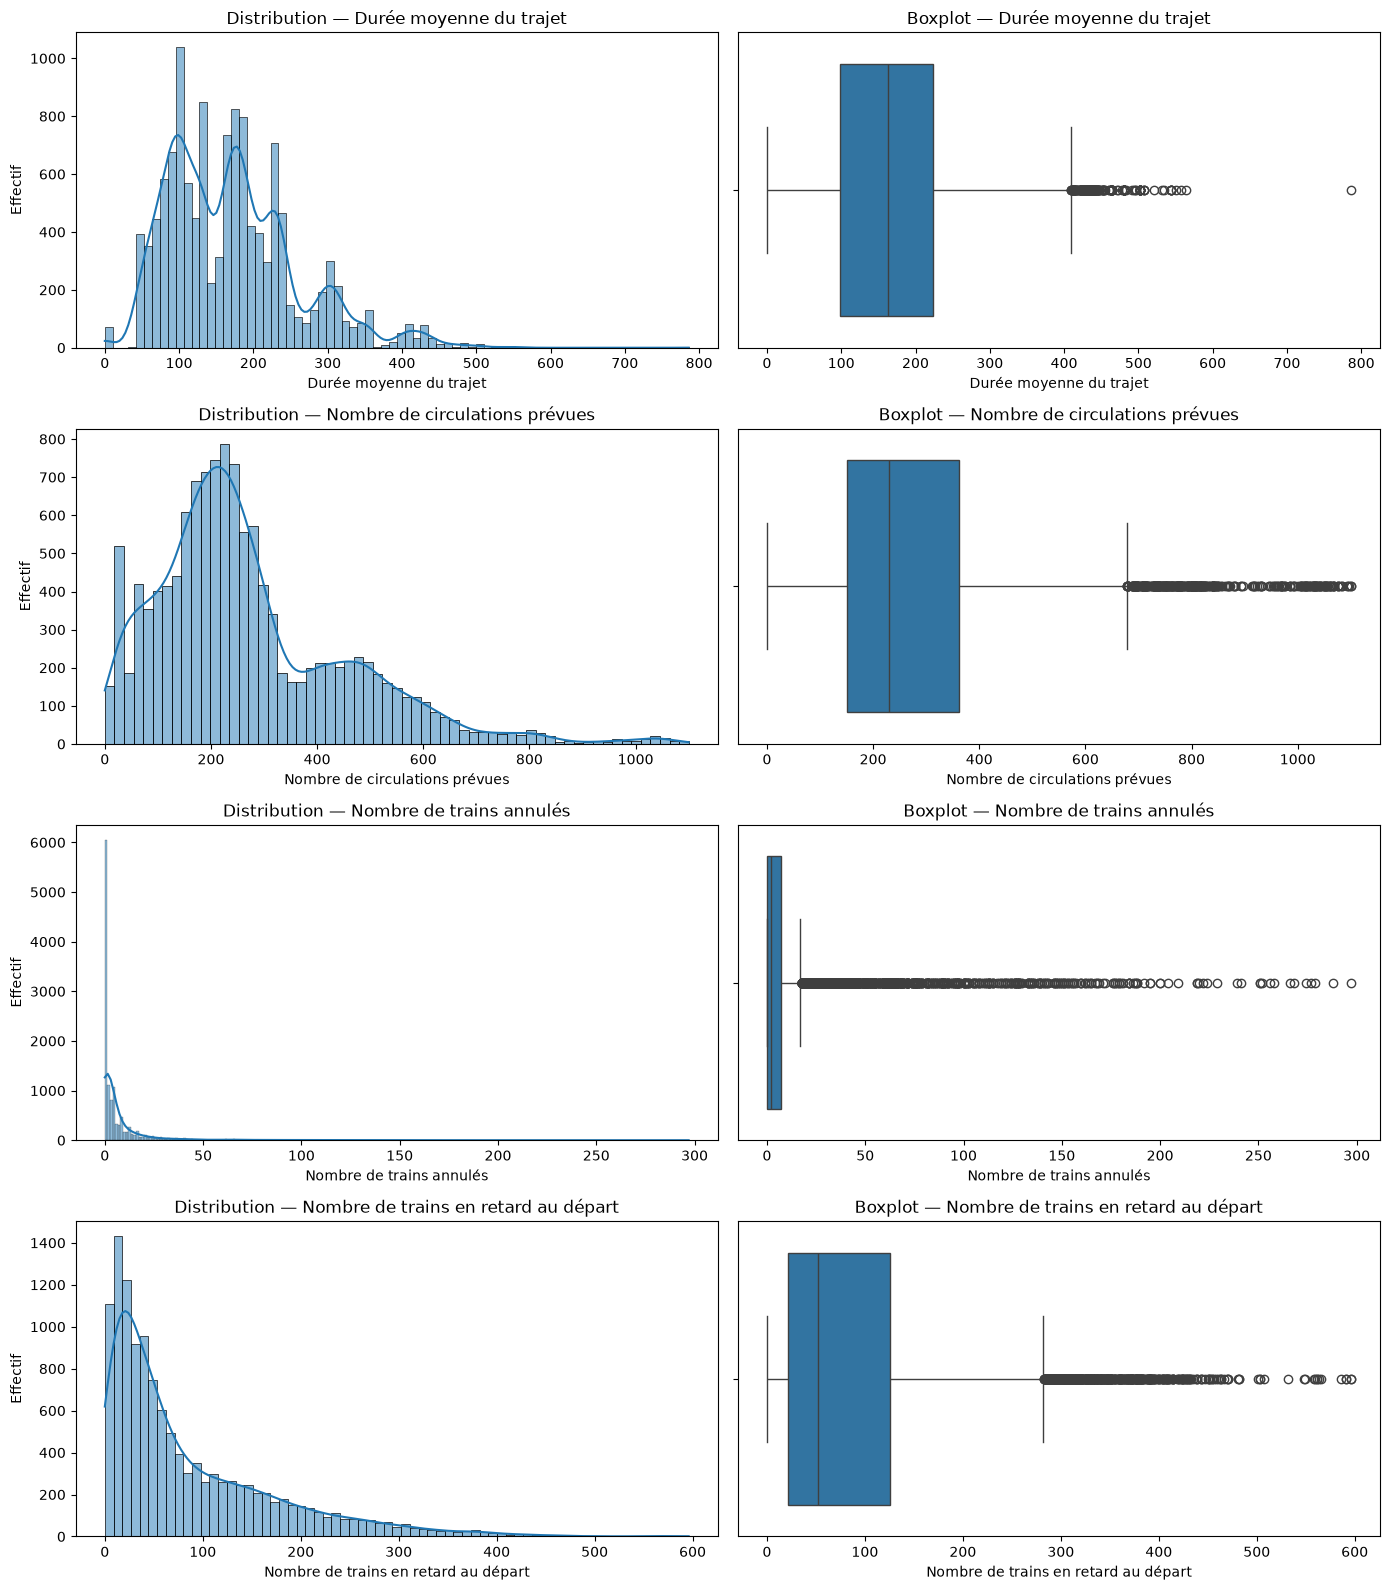

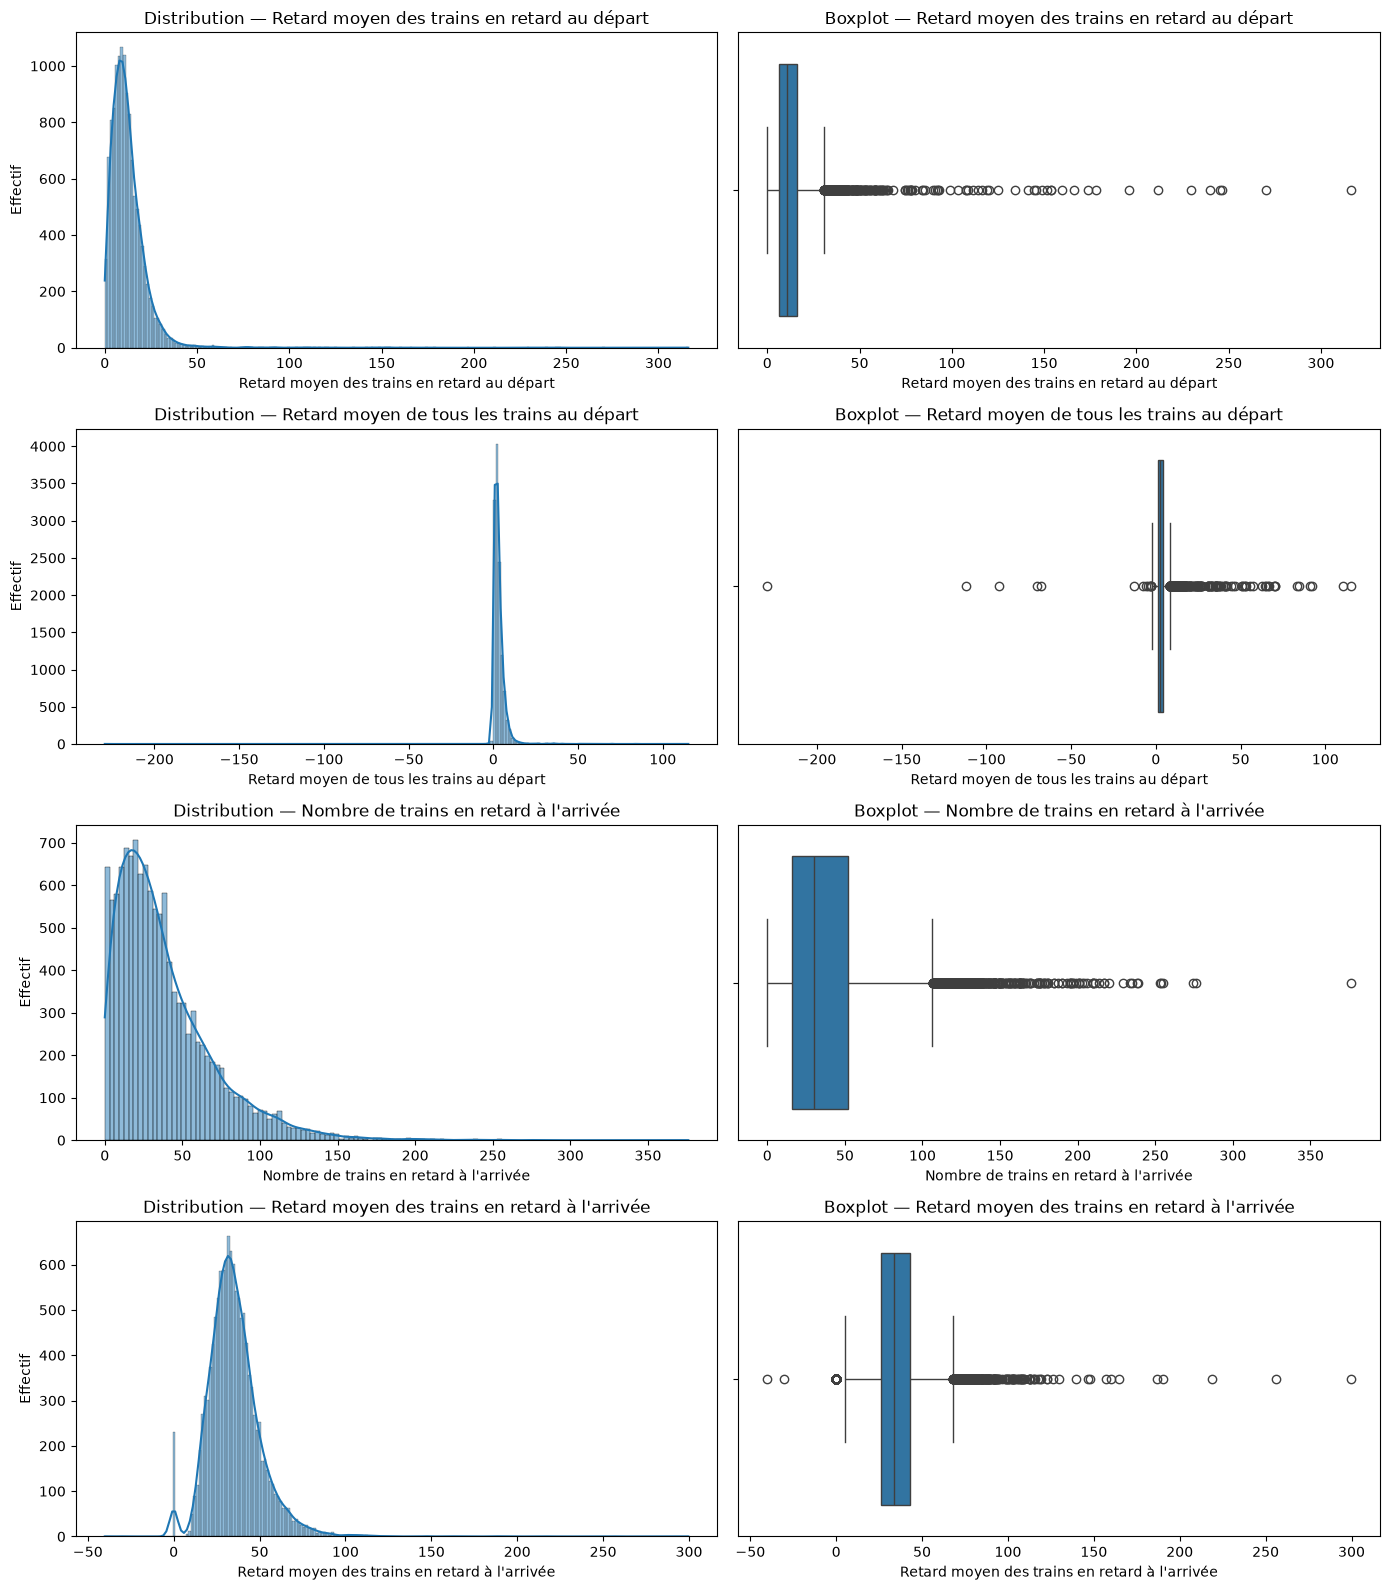

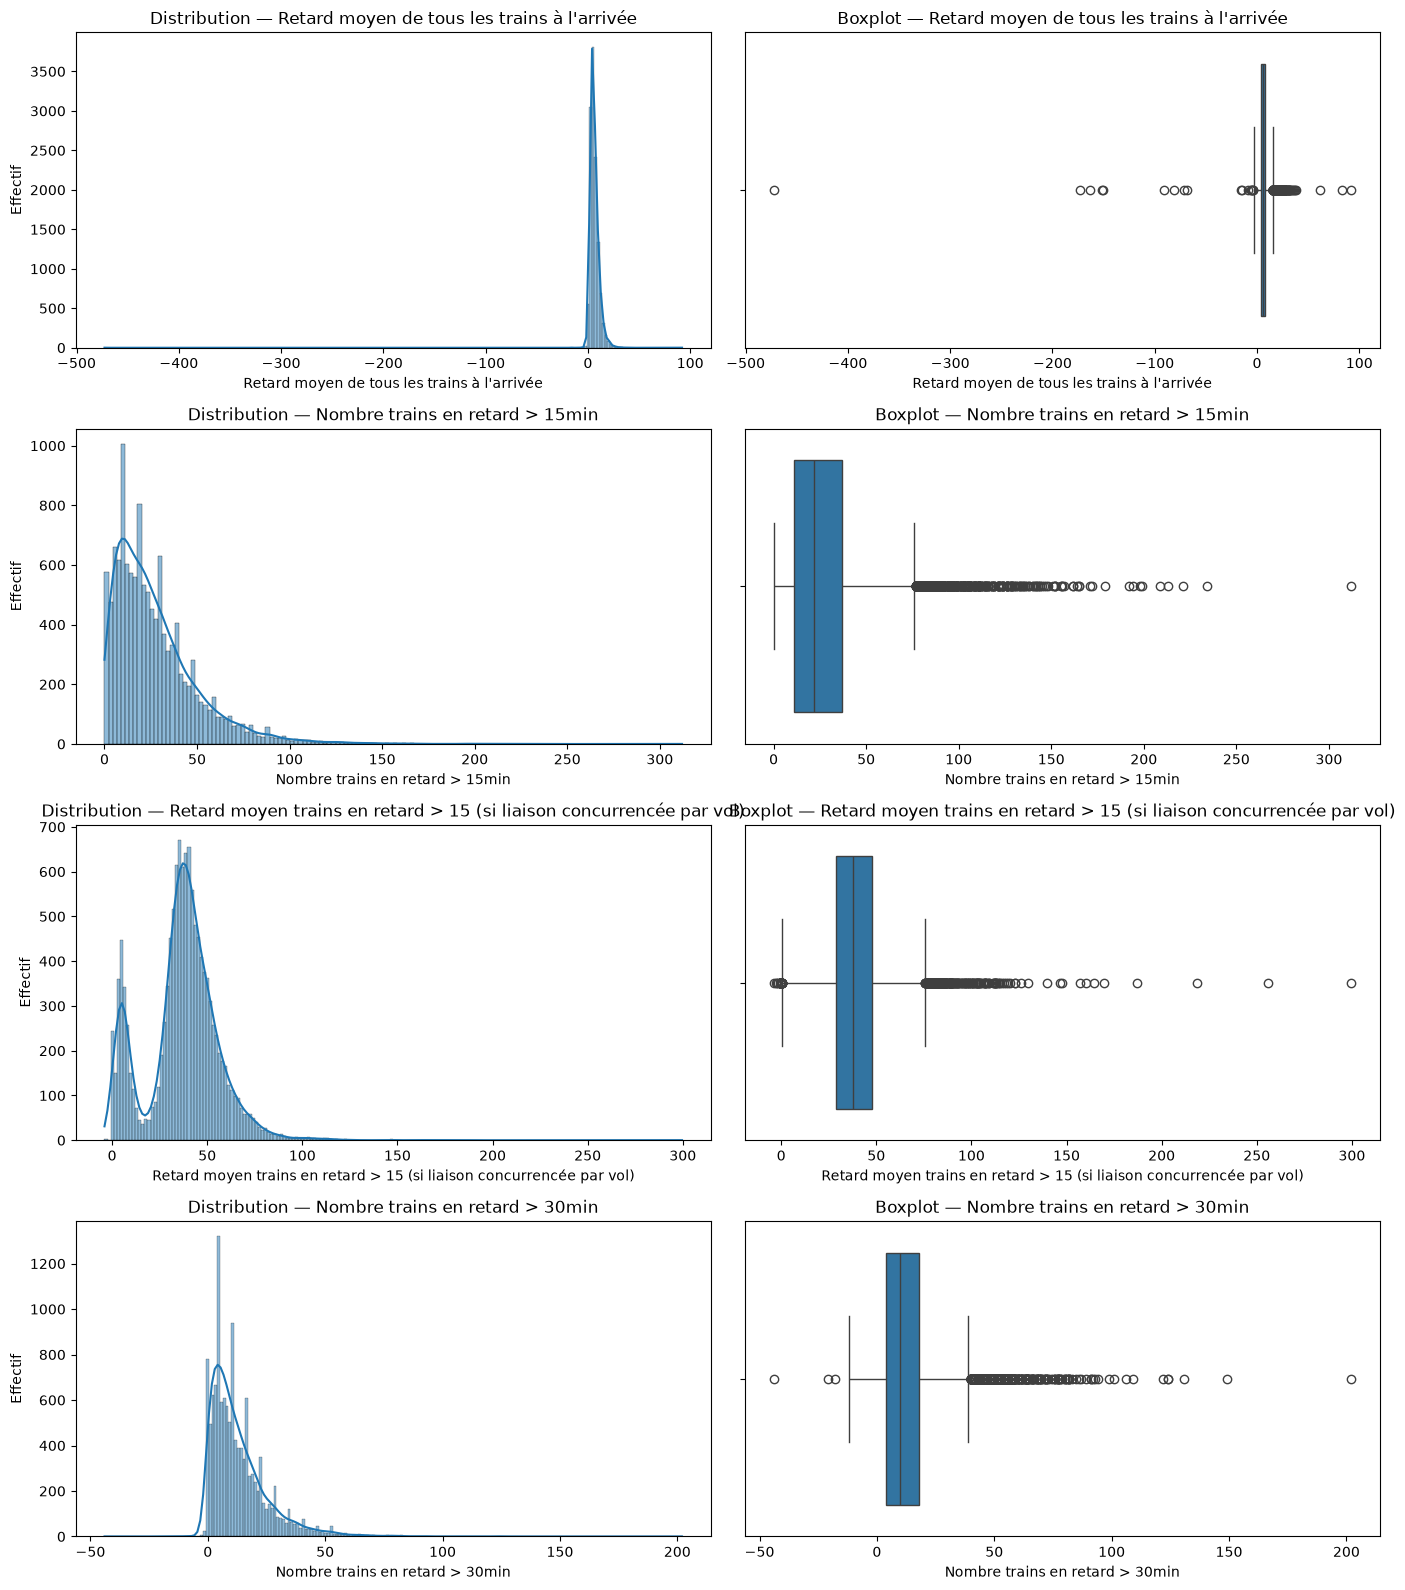

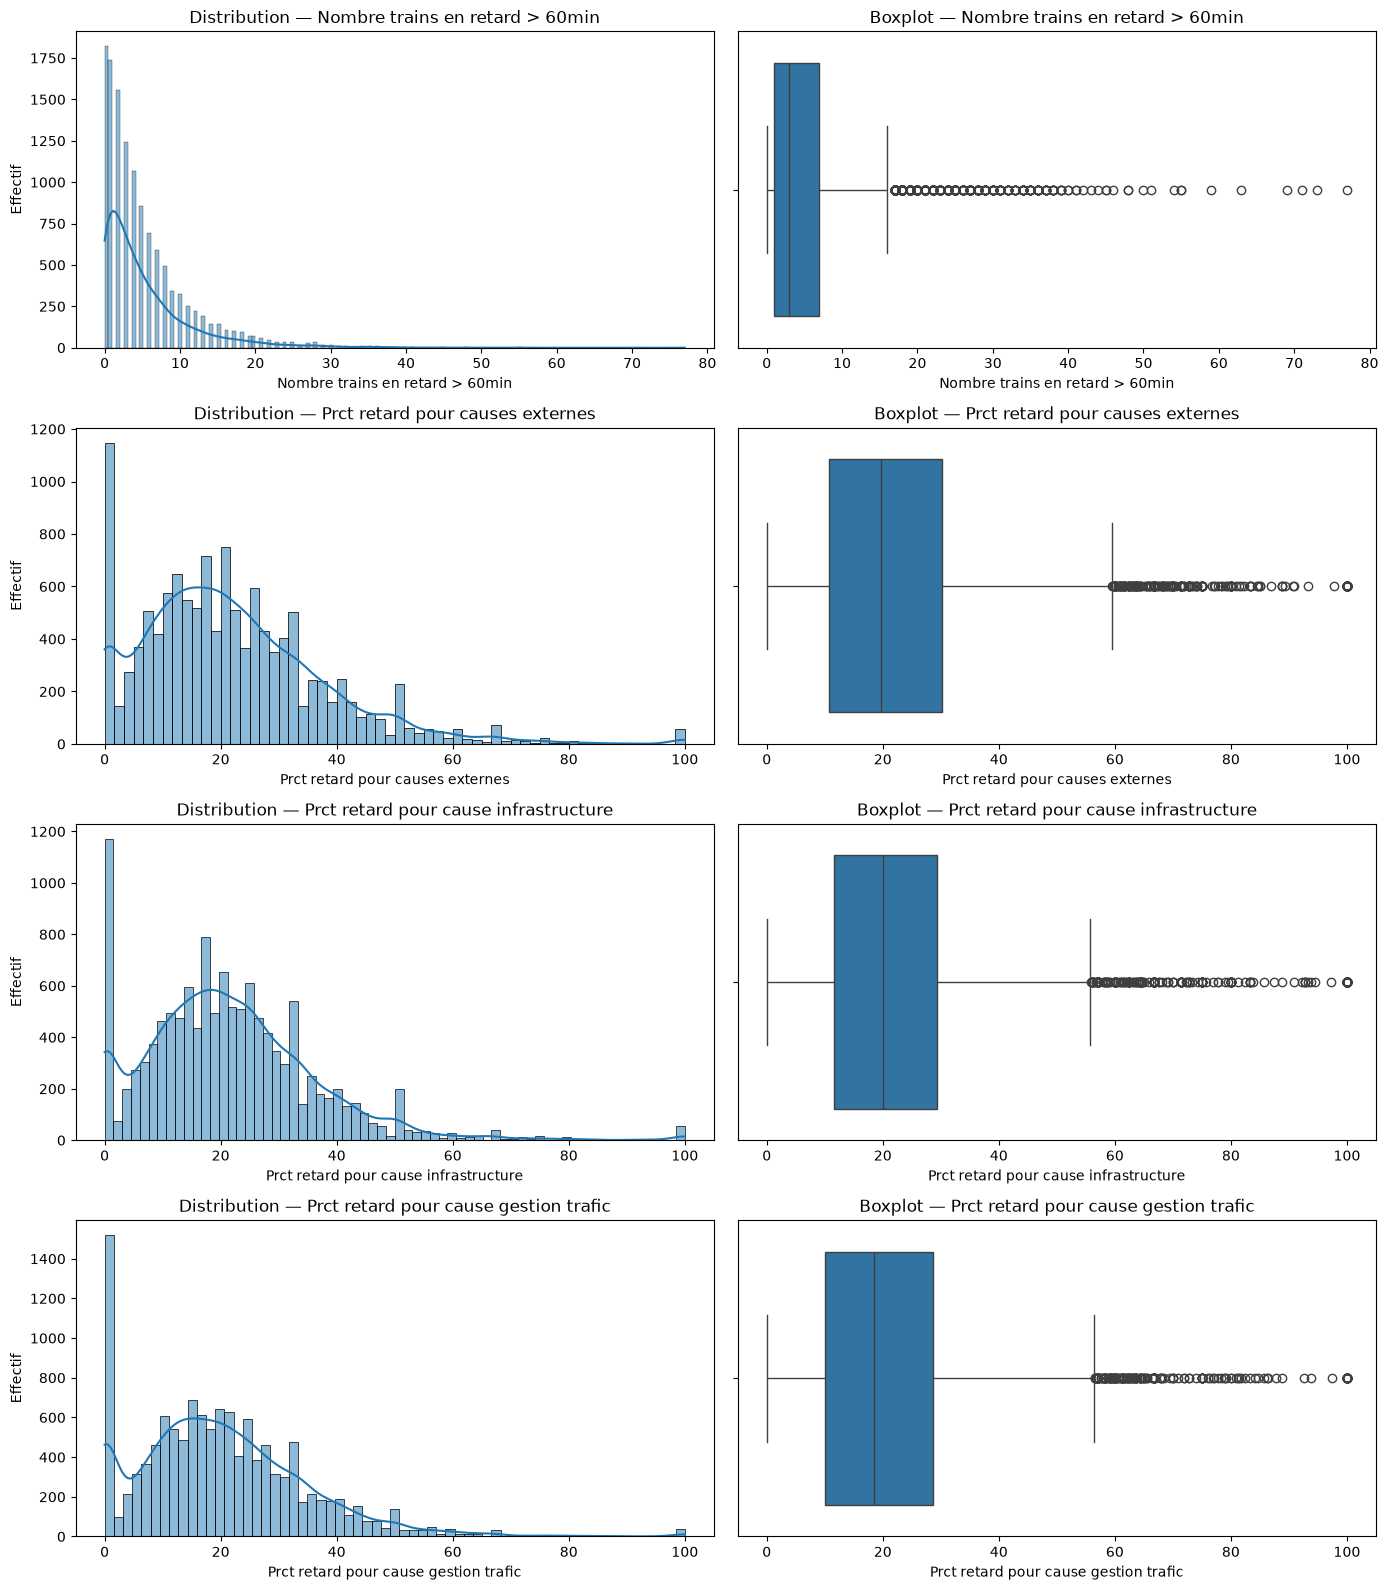

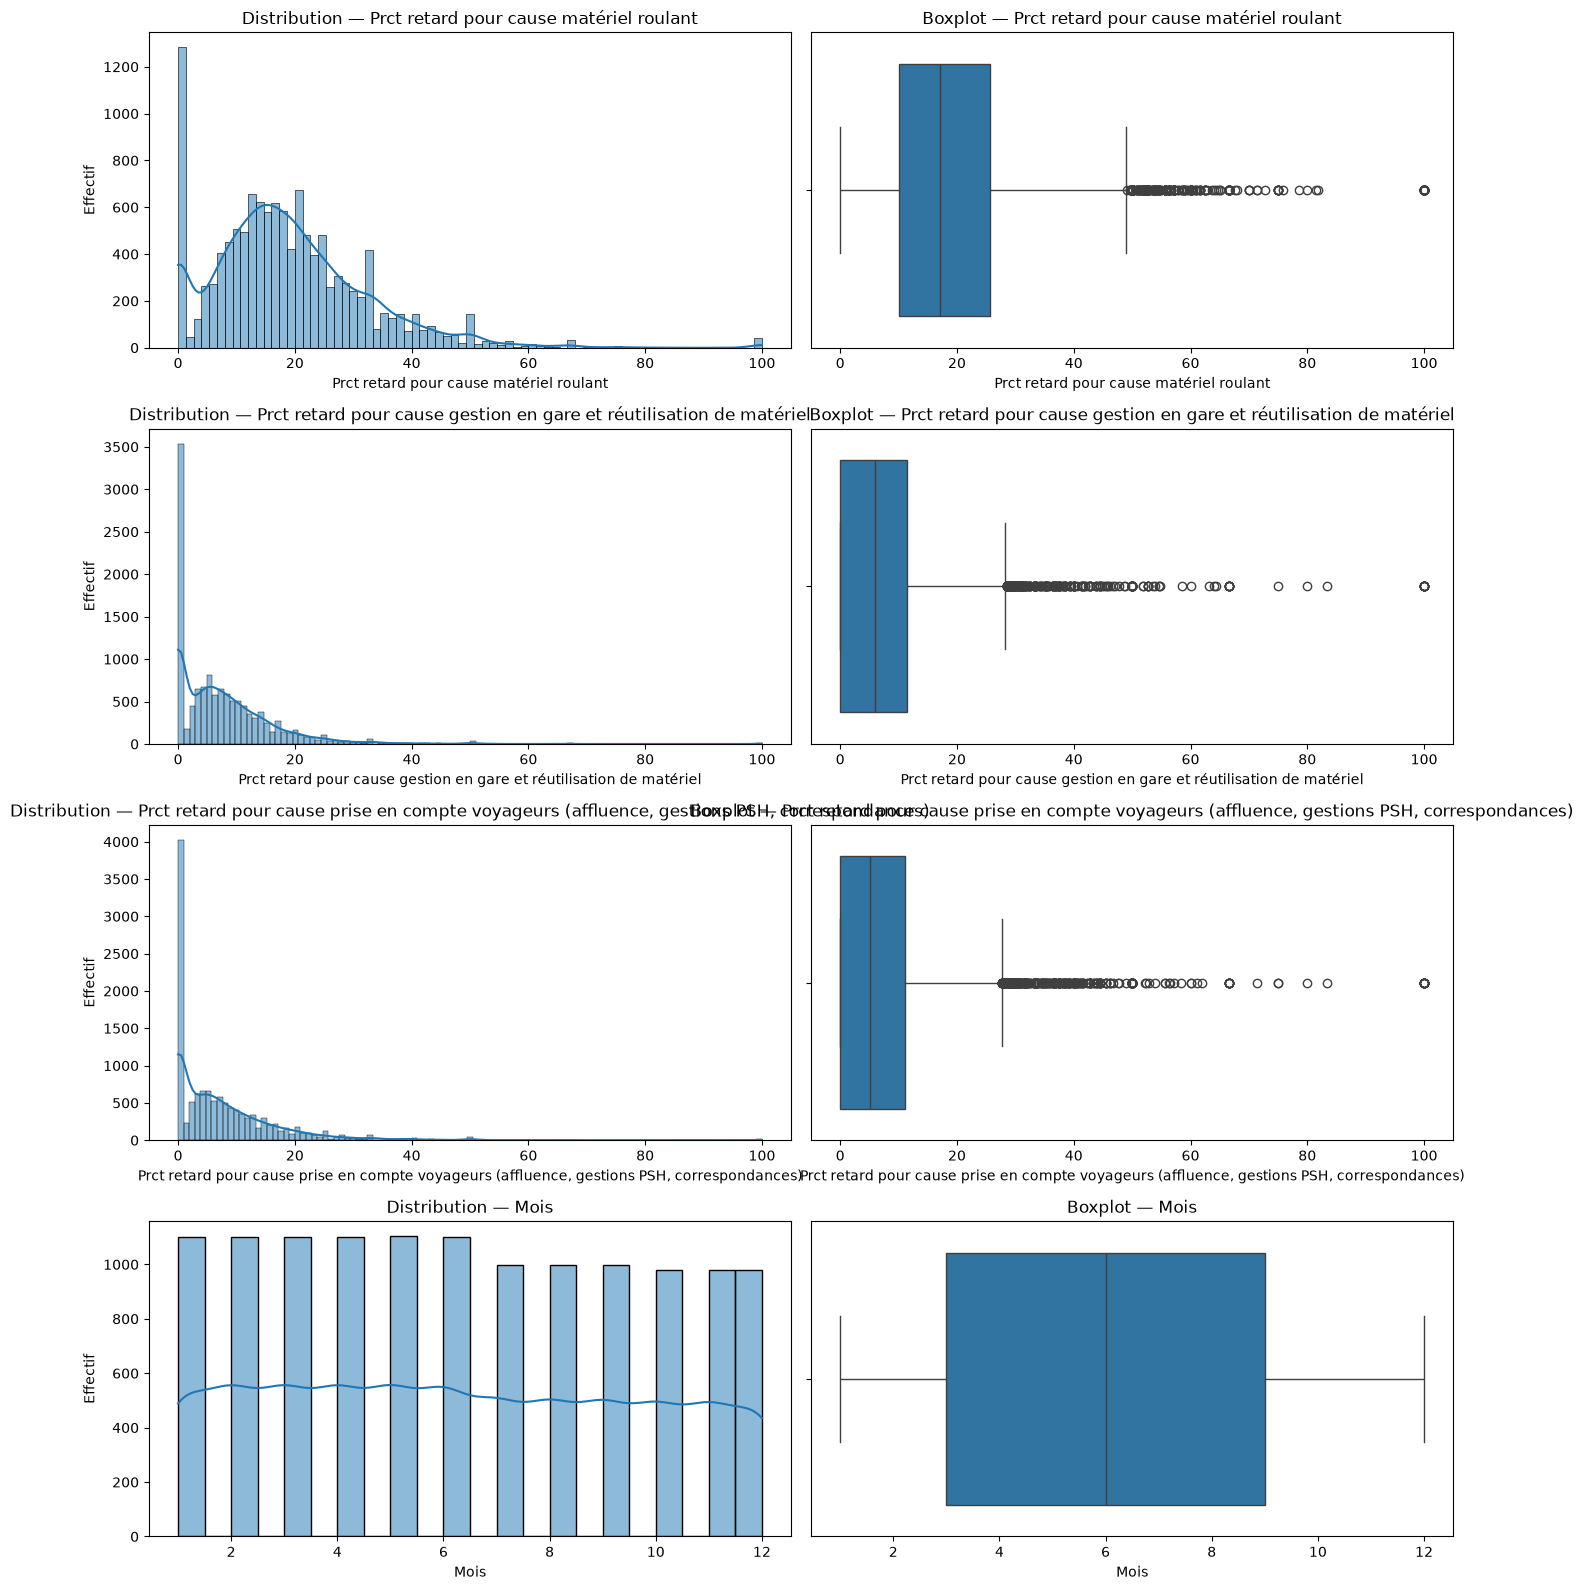

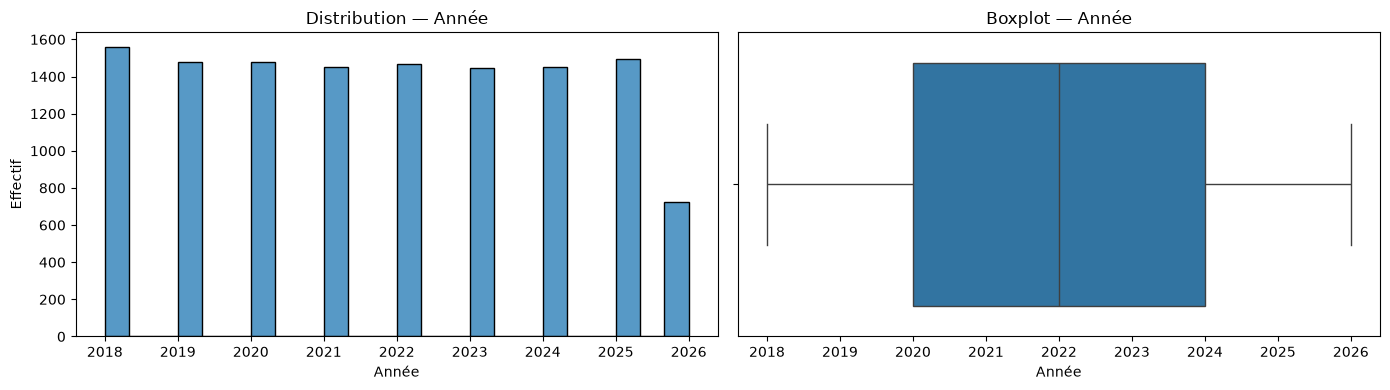


Service — Dataset
               Effectif  Pourcentage (%)
Service                                 
National          11012            87.79
International      1532            12.21


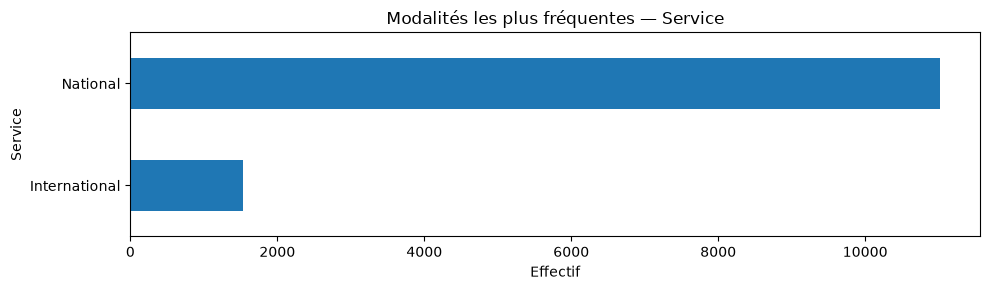


Gare de départ — Dataset
                           Effectif  Pourcentage (%)
Gare de départ                                      
PARIS LYON                     2560            20.41
PARIS MONTPARNASSE             1632            13.01
LYON PART DIEU                  615             4.90
PARIS EST                       615             4.90
MARSEILLE ST CHARLES            557             4.44
PARIS NORD                      408             3.25
LILLE                           306             2.44
RENNES                          216             1.72
NANTES                          216             1.72
BORDEAUX ST JEAN                214             1.71
STRASBOURG                      207             1.65
MONTPELLIER                     204             1.63
MARNE LA VALLEE                 204             1.63
TOURCOING                       113             0.90
MACON LOCHE                     105             0.84
DIJON VILLE                     105             0.84
MULHOUSE VILLE      

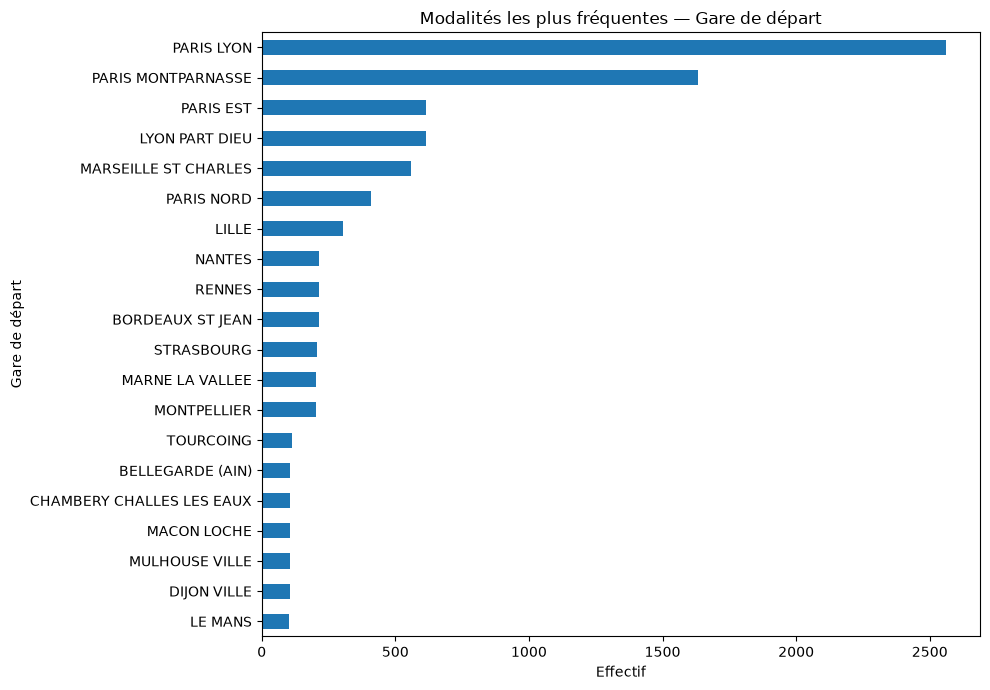


Gare d'arrivée — Dataset
                           Effectif  Pourcentage (%)
Gare d'arrivée                                      
PARIS LYON                     2560            20.41
PARIS MONTPARNASSE             1632            13.01
PARIS EST                       615             4.90
LYON PART DIEU                  615             4.90
MARSEILLE ST CHARLES            469             3.74
PARIS NORD                      408             3.25
LILLE                           306             2.44
NANTES                          216             1.72
RENNES                          216             1.72
BORDEAUX ST JEAN                214             1.71
STRASBOURG                      207             1.65
MARNE LA VALLEE                 204             1.63
MONTPELLIER                     204             1.63
TOURCOING                       201             1.60
CHAMBERY CHALLES LES EAUX       105             0.84
BELLEGARDE (AIN)                105             0.84
DIJON VILLE         

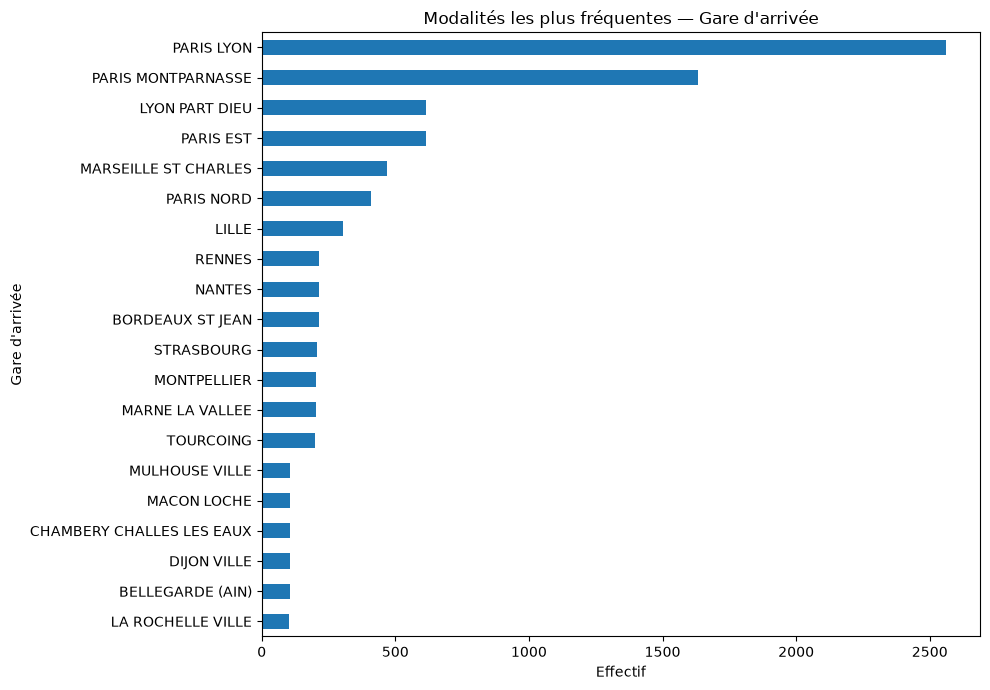

{'numeriques': ['Durée moyenne du trajet',
  'Nombre de circulations prévues',
  'Nombre de trains annulés',
  'Nombre de trains en retard au départ',
  'Retard moyen des trains en retard au départ',
  'Retard moyen de tous les trains au départ',
  "Nombre de trains en retard à l'arrivée",
  "Retard moyen des trains en retard à l'arrivée",
  "Retard moyen de tous les trains à l'arrivée",
  'Nombre trains en retard > 15min',
  'Retard moyen trains en retard > 15 (si liaison concurrencée par vol)',
  'Nombre trains en retard > 30min',
  'Nombre trains en retard > 60min',
  'Prct retard pour causes externes',
  'Prct retard pour cause infrastructure',
  'Prct retard pour cause gestion trafic',
  'Prct retard pour cause matériel roulant',
  'Prct retard pour cause gestion en gare et réutilisation de matériel',
  'Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)',
  'Mois',
  'Année'],
 'categorielles': ['Service', 'Gare de départ', "Gare d'arrivée

In [40]:
analyse_exploratoire(data)